# 2. ¿Qué equipos ganan y pierden partidos en la segunda parte?

**Pregunta:** si los partidos terminaran en el descanso, ¿cómo cambiaría la clasificación? ¿Qué equipos remontan más y cuáles dejan escapar ventajas?

Comparamos los puntos reales de cada equipo con los que tendría si el resultado del minuto 45 fuera el final.

*Limitación: a unos 25-40 partidos por temporada les falta el resultado al descanso en la fuente; se excluyen de este análisis.*

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MARTS, IMG = ROOT / "data" / "marts", ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
for t in ["fct_matches", "fct_standings_by_matchday", "fct_final_standings", "mart_home_advantage", "mart_comebacks"]:
    con.execute(f"create view {t} as select * from '{MARTS / (t + '.parquet')}'")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
q = lambda sql: con.execute(sql).df()

## En toda la liga: ¿cuánto se mantiene el resultado del descanso?

In [2]:
q("""
    select outcome_ht as al_descanso,
           count(*) as partidos,
           avg((outcome = 'local')::int)     as acaba_victoria_local,
           avg((outcome = 'empate')::int)    as acaba_empate,
           avg((outcome = 'visitante')::int) as acaba_victoria_visitante
    from fct_matches where outcome_ht is not null group by 1 order by 1
""").style.format({c: "{:.1%}" for c in ["acaba_victoria_local", "acaba_empate", "acaba_victoria_visitante"]})

,al_descanso,partidos,acaba_victoria_local,acaba_empate,acaba_victoria_visitante
0,empate,1907,45.9%,22.8%,31.3%
1,local,1853,79.6%,14.6%,5.8%
2,visitante,1221,10.4%,21.4%,68.2%


## Por equipo (equipos con al menos 5 temporadas en Primera desde 2012-13)

In [3]:
teams = q("""
    select team as equipo,
           count(distinct season) as temporadas,
           sum(matches_with_ht) as partidos,
           sum(comebacks) as remontadas,
           sum(losing_at_ht) as perdiendo_al_descanso,
           sum(comebacks) / sum(losing_at_ht) as pct_remonta,
           sum(blown_leads) as ventajas_perdidas,
           sum(winning_at_ht) as ganando_al_descanso,
           sum(blown_leads) / sum(winning_at_ht) as pct_pierde_ventaja,
           38.0 * sum(second_half_points_delta) / sum(matches_with_ht) as puntos_2a_parte_por_temporada
    from mart_comebacks group by team having count(distinct season) >= 5
    order by puntos_2a_parte_por_temporada desc""")
teams.style.format({"pct_remonta": "{:.0%}", "pct_pierde_ventaja": "{:.0%}", "puntos_2a_parte_por_temporada": "{:+.1f}"})

,equipo,temporadas,partidos,remontadas,perdiendo_al_descanso,pct_remonta,ventajas_perdidas,ganando_al_descanso,pct_pierde_ventaja,puntos_2a_parte_por_temporada
0,Barcelona,15,518.000000,38.000000,76.000000,50%,24.000000,278.000000,9%,+16.9
1,Atlético de Madrid,15,503.000000,28.000000,72.000000,39%,30.000000,213.000000,14%,+15.9
2,Real Madrid,15,513.000000,36.000000,74.000000,49%,20.000000,267.000000,7%,+15.2
3,Sevilla,15,507.000000,46.000000,142.000000,32%,41.000000,162.000000,25%,+8.5
4,Villarreal,14,460.000000,40.000000,128.000000,31%,37.000000,171.000000,22%,+6.8
5,Betis,14,459.000000,38.000000,137.000000,28%,36.000000,134.000000,27%,+5.2
6,Getafe,14,447.000000,27.000000,164.000000,16%,25.000000,100.000000,25%,+4.8
7,Real Sociedad,15,495.000000,37.000000,133.000000,28%,42.000000,171.000000,25%,+3.7
8,Valencia,15,505.000000,47.000000,143.000000,33%,39.000000,153.000000,25%,+3.5
9,Athletic Club,15,486.000000,38.000000,137.000000,28%,37.000000,171.000000,22%,+3.4


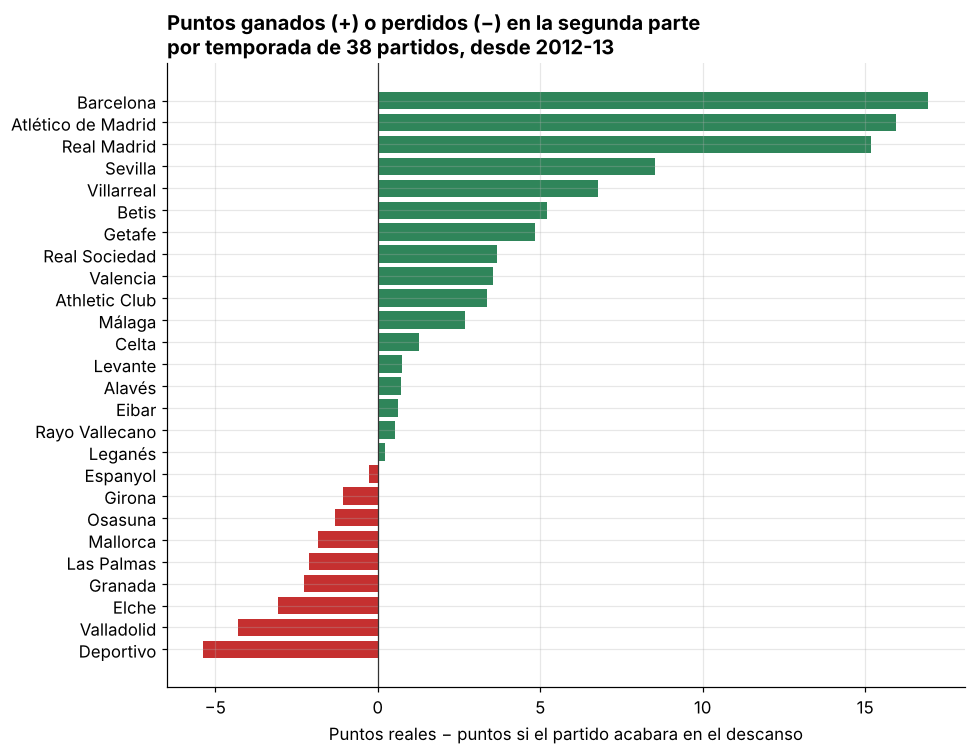

In [4]:
t = teams.sort_values("puntos_2a_parte_por_temporada")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(t.equipo, t.puntos_2a_parte_por_temporada,
        color=["#2f855a" if v > 0 else "#c53030" for v in t.puntos_2a_parte_por_temporada])
ax.axvline(0, color="#333", lw=.8)
ax.set_title("Puntos ganados (+) o perdidos (−) en la segunda parte\npor temporada de 38 partidos, desde 2012-13",
             loc="left", fontweight="bold")
ax.set_xlabel("Puntos reales − puntos si el partido acabara en el descanso")
plt.tight_layout(); fig.savefig(IMG / "segunda_parte.png", dpi=150); plt.show()

## Conclusiones

- El resultado del descanso pesa mucho: el local que gana al descanso acaba ganando el **80 %** de las veces; el visitante que va ganando, el **68 %**.
- Barcelona (+16,9), Atlético (+15,9) y Real Madrid (+15,2) suman unos 15-17 puntos por temporada en las segundas partes. Además casi nunca dejan escapar una ventaja (entre el 7 % y el 14 % de las veces).
- En el otro extremo, Deportivo (−5,4), Valladolid (−4,3) y Elche (−3,1) pierden puntos tras el descanso de forma sistemática.
- Remontar se parece más a un reflejo de la calidad de la plantilla que a un rasgo de "carácter". Un siguiente paso sería controlar por el nivel del rival.